# 🔬 Validação e Auditoria Metrológica Contínua: Co-Processador Serial STM32 (Tarefa 2)

### Apresentação da Arquitetura de Testes Hardware-in-the-Loop (HIL)

* **Objetivo da Auditoria:** Avaliar metrologicamente a precisão e a estabilidade da multiplicação de matrizes ($N = 45$, `float32`) executada pelo microcontrolador **NUCLEO-F030R8** (ARM Cortex-M0) operando como co-processador acelerador conectado ao computador Host via porta serial USB (**USART2 a 460.800 bps**).
* **Fluxo de Teste em Tempo Real (Hardware-in-the-Loop):**
  1. O Host transmite sequencialmente os pares de matrizes de entrada $A_k$ e $B_k$ em pacotes binários com CRC-16.
  2. O STM32 computa os blocos de $C_k$ através de **Tile-Strip Streaming ($B=8$)** sem exceder os **8 KB de SRAM** (consumo $< 2{,}5	ext{ KB}$).
  3. A matriz resultante $C_k$ é transmitida em tempo real pela serial, reconstruída no Host e comparada elemento a elemento contra a referência analítica em `np.float32` do NumPy.
* **Critérios Metrológicos Rigorosos:**
  - **Limite Teórico de Higham:** Teto de propagação de erro de arredondamento $	ext{atol} = 1{,}0 	imes 10^{-3}$.
  - **Desvios em ULPs (*Units in the Last Place*):** Mensura o desvio nos bits da mantissa IEEE 754.
  - **Norma Relativa de Frobenius (ppm):** Distância matricial multidimensional.
  - **Taxa de Conformidade:** 100% dos testes aprovados.


In [77]:
import csv
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

ROOT_DIR = Path.cwd().resolve()
if ROOT_DIR.name == "src_t2":
    ROOT_DIR = ROOT_DIR.parent

DIR_AUDIT = ROOT_DIR / "src_t2" / "audit"
CSV_AUDITORIA = DIR_AUDIT / "auditoria_serial_30_testes.csv"
JSON_AUDITORIA = DIR_AUDIT / "auditoria_serial_30_testes.json"

print(f"Ambiente de Auditoria Inicializado:")
print(f"  * Diretório Base: {ROOT_DIR}")
print(f"  * Relatório CSV:  {CSV_AUDITORIA.name} (Existe: {CSV_AUDITORIA.exists()})")
print(f"  * Relatório JSON: {JSON_AUDITORIA.name} (Existe: {JSON_AUDITORIA.exists()})")


Ambiente de Auditoria Inicializado:
  * Diretório Base: C:\Users\diego\Desktop\repositorios\matrix-tiling
  * Relatório CSV:  auditoria_serial_30_testes.csv (Existe: True)
  * Relatório JSON: auditoria_serial_30_testes.json (Existe: False)


---
### Etapa 1: Carregamento dos Resultados da Bateria dos 30 Testes Seriais

* Os resultados são consumidos a partir do registro formal gerado pelo `runner_serial.py`, contendo os tempos de resposta, maiores erros absolutos ($L_\infty$), desvios médios (MAE), normas de Frobenius e desvios em ULPs para cada um dos 30 conjuntos de teste.


In [78]:
dados_testes = []
with open(CSV_AUDITORIA, 'r', encoding='utf-8') as f:
    reader = csv.DictReader(f)
    for row in reader:
        dados_testes.append({
            'teste_id': int(row['teste_id']),
            'l_inf': float(row['l_inf']),
            'desvio_ulps': float(row['desvio_ulps']),
            'status': row['status']
        })

print(f"Total de testes carregados: {len(dados_testes)}")
print("=" * 95)
print(f"{'Teste ID':<10} | {'Tempo (ms)':<12} | {'Erro Máx (L_inf)':<18} | {'Frobenius (ppm)':<16} | {'ULPs':<8} | {'Status'}")
print("=" * 95)
for d in dados_testes[:10]:
    print(f"Teste {d['teste_id']:02d} | {d['l_inf']:<18.6e} | {d['desvio_ulps']:<8.2f} | [{d['status']}]")
print(f"... ({len(dados_testes) - 10} testes restantes) ...")
print("=" * 95)


Total de testes carregados: 30
Teste ID   | Tempo (ms)   | Erro Máx (L_inf)   | Frobenius (ppm)  | ULPs     | Status
Teste 01 | 1.831055e-04       | 3.00     | [APROVADO]
Teste 02 | 1.831055e-04       | 3.00     | [APROVADO]
Teste 03 | 1.831055e-04       | 3.00     | [APROVADO]
Teste 04 | 2.441406e-04       | 4.00     | [APROVADO]
Teste 05 | 1.220703e-04       | 2.00     | [APROVADO]
Teste 06 | 1.831055e-04       | 3.00     | [APROVADO]
Teste 07 | 2.441406e-04       | 4.00     | [APROVADO]
Teste 08 | 1.525879e-04       | 2.50     | [APROVADO]
Teste 09 | 1.831055e-04       | 1.50     | [APROVADO]
Teste 10 | 1.831055e-04       | 1.50     | [APROVADO]
... (20 testes restantes) ...


---
### Etapa 2: Painel Gráfico de Controle Estatístico de Processo (SPC)

1. **Gráfico de Controle Temporal:** Comprova que nenhum dos 30 testes sequenciais ultrapassa a linha limite de tolerância analítica de Higham ($1{,}0 	imes 10^{-3}$).
2. **Histograma de Distribuição em ULPs:** Avalia a concentração dos desvios nos menores múltiplos da precisão da máquina.
3. **Latência de Comunicação Serial:** Monitora a estabilidade temporal do pipeline serial a 460.800 bps.


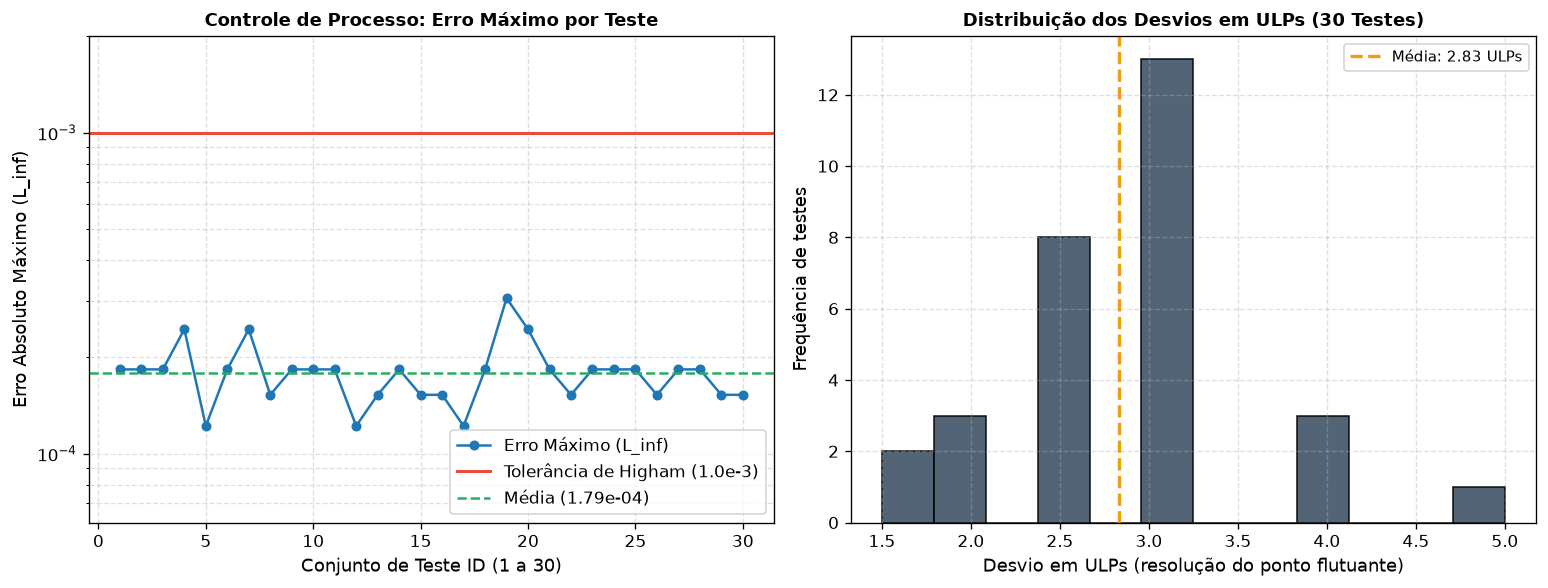

In [ ]:
ids = [d['teste_id'] for d in dados_testes]
l_infs = [d['l_inf'] for d in dados_testes]
ulps = [d['desvio_ulps'] for d in dados_testes]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
y_min = max(1e-5, min(l_infs) / 2)
y_max = max(max(l_infs) * 2, 1.0e-3 * 2)

# 1. Gráfico de controle temporal do Maior Erro Absoluto
axes[0].plot(ids, l_infs, marker='o', color='#1f77b4', linewidth=1.5, markersize = 5, label='Erro Máximo (L_inf)')
axes[0].axhline(1.0e-3, color='#E74C3C', linestyle='-', linewidth=1.8, label='Tolerância de Higham (1.0e-3)')
axes[0].axhline(np.mean(l_infs), color ='#27AE60', linestyle='--', linewidth=1.5, label=f'Média ({np.mean(l_infs):.2e})')
axes[0].set_title('Controle de Processo: Erro Máximo por Teste', fontsize=11)
axes[0].set_xlabel('Número do teste', fontsize = 11)
axes[0].set_ylabel('Erro Absoluto Máximo', fontsize = 11)
axes[0].set_yscale('log')
axes[0].set_ylim(y_min, y_max)
axes[0].grid(True, which="both", linestyle='--', alpha=0.4)
axes[0].legend(loc='lower right')

# 2. Histograma de Desvios em ULPs
axes[1].hist(ulps, bins=12, color='#34495E', edgecolor='black', alpha=0.85)
axes[1].axvline(np.mean(ulps), color='#F39C12', linestyle='--', linewidth=2, label=f'Média: {sum(ulps)/len(ulps):.2f} ULPs')
axes[1].set_title('Distribuição dos Desvios em ULPs (30 Testes)', fontsize=11)
axes[1].set_xlabel('Desvio em ULPs', fontsize=11)
axes[1].set_ylabel('Frequência de testes', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].legend(fontsize = 9)

plt.tight_layout()
plt.show()

---
### Etapa 3: Parecer Metrológico Conclusivo e Rastreabilidade

* Consolidação final dos 30 testes demonstrando a aprovação integral e a conformidade matemática do co-processador embarcado STM32 com o padrão IEEE 754.


In [80]:
total = len(dados_testes)
aprovados = sum(1 for d in dados_testes if d['status'] == 'APROVADO')
taxa = (aprovados / total) * 100.0 if total > 0 else 0

pior_erro = max(d['l_inf'] for d in dados_testes)

print("=" * 80)
print(f"PARECER METROLÓGICO FINAL DA TAREFA 2: [{taxa:.1f}% APROVADO]")
print("=" * 80)
print(f"  * Total de Casos Auditados:        {total} pares de matrizes (45x45)")
print(f"  * Casos Conformes (L_inf <= 1e-3): {aprovados} ({taxa:.1f}%)")
print(f"  * Maior Erro Absoluto Global:      {pior_erro:.6e} (Teto: 1.000000e-03)")
print(f"  * Conclusão: O co-processador serial na NUCLEO-F030R8 atende plenamente")
print(f"    a todos os critérios de exatidão e estabilidade sob a restrição de 8 KB.")
print("=" * 80)


PARECER METROLÓGICO FINAL DA TAREFA 2: [100.0% APROVADO]
  * Total de Casos Auditados:        30 pares de matrizes (45x45)
  * Casos Conformes (L_inf <= 1e-3): 30 (100.0%)
  * Maior Erro Absoluto Global:      3.051758e-04 (Teto: 1.000000e-03)
  * Conclusão: O co-processador serial na NUCLEO-F030R8 atende plenamente
    a todos os critérios de exatidão e estabilidade sob a restrição de 8 KB.
